Set the batch size, analyst limits, and costs. We use five analysts, each with 10 review slots per batch of 200 applications. Approving fraud costs 100 units, rejecting a legitimate application costs 10, and each human review adds 0.5.


In [2]:
SEED = 42
BATCH_SIZE = 200
N_ANALYSTS = 5
ANALYSTS = [f"standard#{j}" for j in range(N_ANALYSTS)]
SLOTS = 10

C_FN = 100.0     # Approve fraud
C_FP = 10.0      # Reject a legitimate application
C_REVIEW = 0.5   # One human review

print("Analysts:", ANALYSTS)
print("Applications per full batch:", BATCH_SIZE)
print("Review slots per analyst:", SLOTS)
print("Maximum reviews per full batch:", N_ANALYSTS * SLOTS)
print("\nAssumed costs:")
print("Fraudulent application approved:", C_FN)
print("Legitimate application rejected:", C_FP)
print("One human review:", C_REVIEW)


Analysts: ['standard#0', 'standard#1', 'standard#2', 'standard#3', 'standard#4']
Applications per full batch: 200
Review slots per analyst: 10
Maximum reviews per full batch: 50

Assumed costs:
Fraudulent application approved: 100.0
Legitimate application rejected: 10.0
One human review: 0.5


Point to the FiFAR data files and create an output folder. Check that both files exist before loading them.


In [3]:
from pathlib import Path

DATA_DIR = Path("FiFAR")
ALERTS_PATH = DATA_DIR / "alert_data" / "processed_data" / "alerts.parquet"
EXPERTS_PATH = DATA_DIR / "synthetic_experts" / "expert_predictions.parquet"
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for path in [ALERTS_PATH, EXPERTS_PATH]:
    print(f"\nChecking: {path.resolve()}")
    print("Exists:", path.exists())
    if not path.exists():
        raise FileNotFoundError(
            f"Could not find:\n{path.resolve()}\n\nChange DATA_DIR to the location of your FiFAR folder."
        )

print("\nOutput folder:", OUTPUT_DIR.resolve())



Checking: C:\Weekend inc\OptiFraud\FiFAR\alert_data\processed_data\alerts.parquet
Exists: True

Checking: C:\Weekend inc\OptiFraud\FiFAR\synthetic_experts\expert_predictions.parquet
Exists: True

Output folder: C:\Weekend inc\OptiFraud\outputs


Load the applications and analyst decisions, then match them by case ID. Check for duplicate IDs, missing analysts, and invalid labels, and look at a few rows.


In [4]:
import pandas as pd
from IPython.display import display

alerts = pd.read_parquet(ALERTS_PATH)
experts = pd.read_parquet(EXPERTS_PATH)

for table in [alerts, experts]:
    if "case_id" in table.columns:
        table.set_index("case_id", inplace=True)
    assert table.index.name == "case_id", "Expected a case_id index."
    assert table.index.is_unique, "Duplicate case IDs found."

missing_analysts = [analyst for analyst in ANALYSTS if analyst not in experts.columns]
if missing_analysts:
    raise ValueError(
        f"Missing analyst columns: {missing_analysts}\n"
        f"Available columns include: {experts.columns[:15].tolist()}"
    )

df = alerts.join(experts[ANALYSTS], how="left", validate="one_to_one")
assert df[["fraud_bool"] + ANALYSTS].isin([0, 1]).all().all(), (
    "Labels or analyst decisions contain missing or nonbinary values."
)

print("Application table shape:", alerts.shape)
print("Expert table shape:", experts.shape)
print("Joined table shape:", df.shape)
print("\nFirst five applications:")
display(alerts.head())
print("\nDecisions from the five selected analysts:")
display(df[["fraud_bool"] + ANALYSTS].head())
print(f"\nFraud prevalence among alerts: {df['fraud_bool'].mean():.1%}")
print("Available month codes:", sorted(df["month"].unique()))


Application table shape: (30622, 33)
Expert table shape: (30622, 50)
Joined table shape: (30622, 38)

First five applications:


,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,model_score,month
case_id,,,,,,,,,,,,,,,,,,,,,
397063,0,0.7,0.210460,-1,378,30,0.011557,-1.424536,AC,2765,...,1000.0,0,INTERNET,2.632512,windows,0,1,0,0.063712,3
397072,0,0.6,0.608326,-1,65,50,0.003009,-1.070189,AC,358,...,1500.0,0,INTERNET,2.741904,windows,0,1,0,0.060329,3
397101,0,0.9,0.864950,-1,78,60,0.011739,-1.019647,AC,909,...,1500.0,0,INTERNET,6.084117,windows,1,1,0,0.556108,3
397126,0,0.1,0.766006,-1,180,60,0.027517,-0.869533,AB,1305,...,1500.0,0,INTERNET,2.127918,windows,0,1,0,0.089685,3
397140,0,0.5,0.192392,-1,70,50,0.001219,15.699609,AA,1920,...,1500.0,0,INTERNET,10.719015,windows,1,1,0,0.074893,3



Decisions from the five selected analysts:


,fraud_bool,standard#0,standard#1,standard#2,standard#3,standard#4
case_id,,,,,,
397063,0,0,0,0,0,0
397072,0,1,0,1,1,1
397101,0,1,1,1,1,1
397126,0,1,0,1,1,1
397140,0,0,0,0,0,0



Fraud prevalence among alerts: 12.1%
Available month codes: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]


Train on the earlier months and save the last month for testing. Split the month before it equally between calibration and validation, keeping similar fraud rates in both halves. Shuffle the evaluation rows to form repeatable batches and check that the splits do not overlap.


In [5]:
import numpy as np
from sklearn.model_selection import train_test_split

ACTION_NAMES = np.array(["Approve", "Reject"] + ANALYSTS)
months = sorted(df["month"].dropna().unique())
train_df = df.loc[df["month"] < months[-2]].copy()
middle_df = df.loc[df["month"] == months[-2]].copy()
cal_df, val_df = train_test_split(middle_df, test_size=0.5, stratify=middle_df["fraud_bool"], random_state=SEED)
test_df = df.loc[df["month"] == months[-1]].copy()
val_df = val_df.sample(frac=1, random_state=SEED)
test_df = test_df.sample(frac=1, random_state=SEED)
splits = {"train": train_df, "calibration": cal_df, "validation": val_df, "test": test_df}

names = list(splits)
for i, name_a in enumerate(names):
    for name_b in names[i + 1:]:
        assert splits[name_a].index.intersection(splits[name_b].index).empty

split_summary = pd.DataFrame([
    {
        "split": name, "applications": len(frame), "first_month": frame["month"].min(),
        "last_month": frame["month"].max(), "fraud_rate": frame["fraud_bool"].mean(),
    }
    for name, frame in splits.items()
]).set_index("split")
display(split_summary.round(3))

preview_cols = ["month", "fraud_bool"] + [
    column for column in ["income", "customer_age", "employment_status"] if column in df.columns
]
for name, frame in splits.items():
    print(f"\n{name.upper()}: first three rows")
    display(frame[preview_cols].head(3))


,applications,first_month,last_month,fraud_rate
split,,,,
train,20765,3,5,0.111
calibration,2700,6,6,0.130
validation,2700,6,6,0.130
test,4457,7,7,0.160



TRAIN: first three rows


,month,fraud_bool,income,customer_age,employment_status
case_id,,,,,
397063,3,0,0.7,30,CB
397072,3,0,0.6,50,CA
397101,3,0,0.9,60,CA



CALIBRATION: first three rows


,month,fraud_bool,income,customer_age,employment_status
case_id,,,,,
804017,6,0,0.9,40,CA
882635,6,0,0.9,50,CC
894990,6,0,0.8,50,CA



VALIDATION: first three rows


,month,fraud_bool,income,customer_age,employment_status
case_id,,,,,
829932,6,0,0.9,40,CB
884158,6,0,0.9,30,CB
825849,6,0,0.9,20,CA



TEST: first three rows


,month,fraud_bool,income,customer_age,employment_status
case_id,,,,,
935715,7,1,0.7,30,CA
935859,7,1,0.9,50,CA
990777,7,0,0.4,20,CA


Prepare the model inputs from the application details, leaving out the outcome, month, and existing model score. Learn the category encoding on the training data, then apply it to every split. `X` holds the inputs, `y` the fraud labels, and `H` the analyst decisions.


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

feature_cols = [column for column in alerts.columns if column not in ["fraud_bool", "month", "model_score"]]
raw_X = df[feature_cols].copy()
cat_cols = raw_X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
for column in cat_cols:
    raw_X[column] = raw_X[column].astype("string").fillna("Missing").astype(str)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32), cat_cols)
    ],
    remainder="passthrough", verbose_feature_names_out=False,
)
preprocessor.fit(raw_X.loc[train_df.index])
X = {name: preprocessor.transform(raw_X.loc[frame.index]).astype(np.float32) for name, frame in splits.items()}
y = {name: frame["fraud_bool"].to_numpy(dtype=int) for name, frame in splits.items()}
H = {name: frame[ANALYSTS].to_numpy(dtype=int) for name, frame in splits.items()}
feature_names = preprocessor.get_feature_names_out()

print("Original feature count:", len(feature_cols))
print("Encoded feature count:", len(feature_names))
print("Categorical features:", cat_cols)
for name in splits:
    print(f"{name:12s} | X: {X[name].shape} | y: {y[name].shape} | H: {H[name].shape}")

print("\nOriginal training features:")
display(raw_X.loc[train_df.index].head())
print("\nFirst eight encoded columns:")
display(pd.DataFrame(X["train"][:5, :8], columns=feature_names[:8], index=train_df.index[:5]))


Original feature count: 30
Encoded feature count: 51
Categorical features: ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']
train        | X: (20765, 51) | y: (20765,) | H: (20765, 5)
calibration  | X: (2700, 51) | y: (2700,) | H: (2700, 5)
validation   | X: (2700, 51) | y: (2700,) | H: (2700, 5)
test         | X: (4457, 51) | y: (4457,) | H: (4457, 5)

Original training features:


,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,...,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count
case_id,,,,,,,,,,,,,,,,,,,,,
397063,0.7,0.210460,-1,378,30,0.011557,-1.424536,AC,2765,5948.746933,...,-1,0,1000.0,0,INTERNET,2.632512,windows,0,1,0
397072,0.6,0.608326,-1,65,50,0.003009,-1.070189,AC,358,229.859982,...,-1,0,1500.0,0,INTERNET,2.741904,windows,0,1,0
397101,0.9,0.864950,-1,78,60,0.011739,-1.019647,AC,909,5028.247673,...,-1,0,1500.0,0,INTERNET,6.084117,windows,1,1,0
397126,0.1,0.766006,-1,180,60,0.027517,-0.869533,AB,1305,5116.919642,...,10,0,1500.0,0,INTERNET,2.127918,windows,0,1,0
397140,0.5,0.192392,-1,70,50,0.001219,15.699609,AA,1920,4951.630457,...,5,0,1500.0,0,INTERNET,10.719015,windows,1,1,0



First eight encoded columns:


,payment_type_AA,payment_type_AB,payment_type_AC,payment_type_AD,payment_type_AE,employment_status_CA,employment_status_CB,employment_status_CC
case_id,,,,,,,,
397063,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
397072,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
397101,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
397126,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
397140,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


Fit an XGBoost model to predict fraud

In [7]:
from xgboost import XGBClassifier

model_params = {
    "n_estimators": 250, "max_depth": 3, "learning_rate": 0.05, "min_child_weight": 20,
    "subsample": 0.85, "colsample_bytree": 0.85, "reg_lambda": 5, "tree_method": "hist",
    "n_jobs": 4, "random_state": SEED,
}
fraud_model = XGBClassifier(objective="binary:logistic", eval_metric="logloss", **model_params)
fraud_model.fit(X["train"], y["train"])

training_preview = pd.DataFrame(
    {
        "actual_fraud": y["train"][:8],
        "raw_fraud_probability": fraud_model.predict_proba(X["train"][:8])[:, 1],
    },
    index=train_df.index[:8],
)
print("Fraud classifier fitted.")
print("\nTraining prediction preview:")
display(training_preview.round(3))


Fraud classifier fitted.

Training prediction preview:


,actual_fraud,raw_fraud_probability
case_id,,
397063,0,0.081
397072,0,0.120
397101,0,0.362
397126,0,0.126
397140,0,0.109
397157,0,0.037
397164,0,0.079
397195,0,0.161


Use the calibration data to fit a sigmoid curve that turns the model's raw scores into fraud probabilities. Apply it to every split and compare a few probabilities before and after calibration.


In [8]:
from sklearn.linear_model import LogisticRegression

calibration_scores = fraud_model.predict(X["calibration"], output_margin=True).reshape(-1, 1)
calibrator = LogisticRegression(C=1e6, max_iter=1000)
calibrator.fit(calibration_scores, y["calibration"])

p = {}
for name in splits:
    raw_scores = fraud_model.predict(X[name], output_margin=True).reshape(-1, 1)
    p[name] = np.clip(calibrator.predict_proba(raw_scores)[:, 1], 1e-6, 1 - 1e-6)

calibration_preview = pd.DataFrame(
    {
        "actual_fraud": y["calibration"][:8],
        "raw_probability": fraud_model.predict_proba(X["calibration"][:8])[:, 1],
        "calibrated_probability": p["calibration"][:8],
    },
    index=cal_df.index[:8],
)
display(calibration_preview.round(3))


,actual_fraud,raw_probability,calibrated_probability
case_id,,,
804017,0,0.093,0.089
882635,0,0.071,0.063
894990,0,0.062,0.054
797201,0,0.082,0.076
812053,0,0.159,0.171
830019,0,0.207,0.234
807825,0,0.141,0.148
806266,1,0.161,0.173


Compare the original and calibrated probabilities on the validation data. The histogram shows how their distributions change; the scatter plot shows the change for each application. 


,original_probability,calibrated_probability,change
0,0.156,0.167,0.011
1,0.084,0.078,-0.006
2,0.059,0.051,-0.008
3,0.104,0.101,-0.002
4,0.057,0.048,-0.009
5,0.036,0.027,-0.009
6,0.120,0.121,0.001
7,0.091,0.086,-0.005
8,0.081,0.074,-0.006
9,0.082,0.076,-0.006


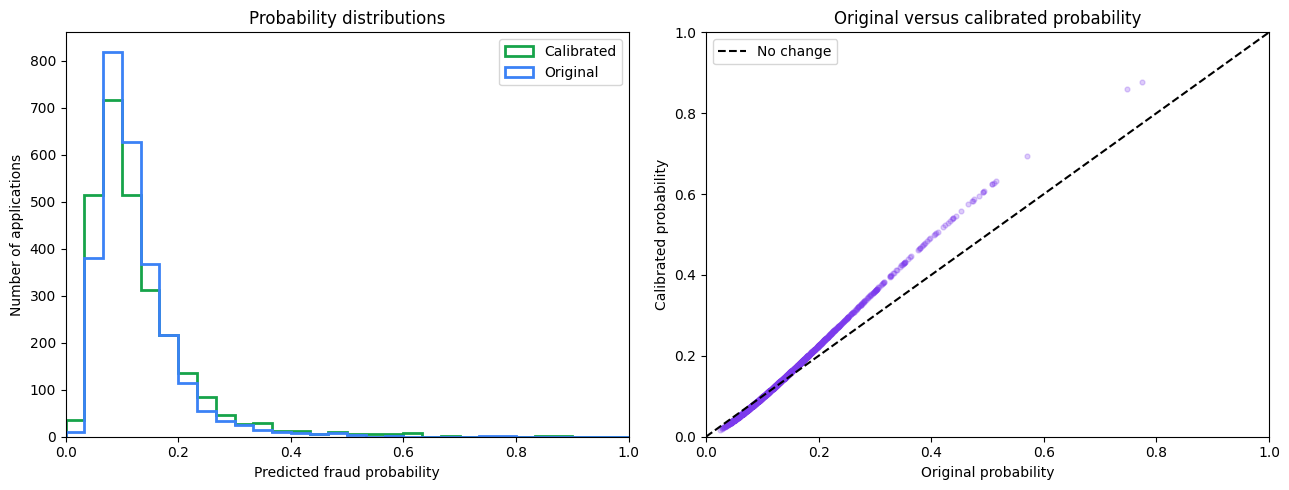

In [9]:
import matplotlib.pyplot as plt

raw_p = fraud_model.predict_proba(X["validation"])[:, 1]
calibrated_p = p["validation"]
comparison = pd.DataFrame({
    "original_probability": raw_p, "calibrated_probability": calibrated_p, "change": calibrated_p - raw_p,
})
display(comparison.head(10).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bins = np.linspace(0, 1, 31)
axes[0].hist(
    [raw_p, calibrated_p], bins=bins, histtype="step", linewidth=2,
    color=["#3b82f6", "#16a34a"], label=["Original", "Calibrated"],
)
axes[0].set(
    title="Probability distributions", xlabel="Predicted fraud probability",
    ylabel="Number of applications", xlim=(0, 1),
)
axes[0].legend()

axes[1].scatter(raw_p, calibrated_p, s=12, alpha=0.25, color="#7c3aed")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="black", label="No change")
axes[1].set(
    title="Original versus calibrated probability", xlabel="Original probability",
    ylabel="Calibrated probability", xlim=(0, 1), ylim=(0, 1),
)
axes[1].legend()
fig.tight_layout()
plt.show()


Calculate what each analyst's mistakes cost on the training data. Then fit one regression model per analyst to estimate their mistake cost for a new application. The review fee is added in the next cell.


In [10]:
from xgboost import XGBRegressor

analyst_training_costs = C_FN * y["train"][:, None] * (1 - H["train"]) + C_FP * (1 - y["train"][:, None]) * H["train"]
print("Analyst decisions on the first training applications:")
display(pd.DataFrame(H["train"][:8], columns=ANALYSTS, index=train_df.index[:8]).assign(actual_fraud=y["train"][:8]))
print("\nCorresponding observed mistake costs:")
display(pd.DataFrame(analyst_training_costs[:8], columns=ANALYSTS, index=train_df.index[:8]))

review_models = []
for j, analyst in enumerate(ANALYSTS):
    model = XGBRegressor(objective="reg:squarederror", **model_params)
    model.fit(X["train"], analyst_training_costs[:, j])
    review_models.append(model)
    print(f"{analyst}: mean observed training mistake cost = {analyst_training_costs[:, j].mean():.2f}")


Analyst decisions on the first training applications:


,standard#0,standard#1,standard#2,standard#3,standard#4,actual_fraud
case_id,,,,,,
397063,0,0,0,0,0,0
397072,1,0,1,1,1,0
397101,1,1,1,1,1,0
397126,1,0,1,1,1,0
397140,0,0,0,0,0,0
397157,0,0,0,0,1,0
397164,1,1,0,1,1,0
397195,1,1,1,1,1,0



Corresponding observed mistake costs:


,standard#0,standard#1,standard#2,standard#3,standard#4
case_id,,,,,
397063,0.0,0.0,0.0,0.0,0.0
397072,10.0,0.0,10.0,10.0,10.0
397101,10.0,10.0,10.0,10.0,10.0
397126,10.0,0.0,10.0,10.0,10.0
397140,0.0,0.0,0.0,0.0,0.0
397157,0.0,0.0,0.0,0.0,10.0
397164,10.0,10.0,0.0,10.0,10.0
397195,10.0,10.0,10.0,10.0,10.0


standard#0: mean observed training mistake cost = 5.34
standard#1: mean observed training mistake cost = 5.07
standard#2: mean observed training mistake cost = 4.50
standard#3: mean observed training mistake cost = 6.16
standard#4: mean observed training mistake cost = 6.63


Estimate the cost of approving, rejecting, or sending each application to an analyst. Approval and rejection costs use the calibrated fraud probability. Review costs use each analyst's predicted mistake cost plus the review fee. Put these seven options into a cost matrix for the optimizer.


In [11]:
costs = {}
for name in ["validation", "test"]:
    predicted_review_cost = np.column_stack([
        np.clip(model.predict(X[name]), 0, max(C_FN, C_FP)) + C_REVIEW for model in review_models
    ])
    costs[name] = np.column_stack([C_FN * p[name], C_FP * (1 - p[name]), predicted_review_cost])
    assert np.isfinite(costs[name]).all()
    assert (costs[name] >= 0).all()

cost_preview = pd.DataFrame(costs["validation"][:8], columns=ACTION_NAMES, index=val_df.index[:8])
cost_preview.insert(0, "fraud_probability", p["validation"][:8])
print("Action order:", ACTION_NAMES.tolist())
print("Validation cost matrix:", costs["validation"].shape)
print("Test cost matrix:", costs["test"].shape)
print("\nPredicted costs for sample validation applications:")
display(cost_preview.round(3))


Action order: ['Approve', 'Reject', 'standard#0', 'standard#1', 'standard#2', 'standard#3', 'standard#4']
Validation cost matrix: (2700, 7)
Test cost matrix: (4457, 7)

Predicted costs for sample validation applications:


,fraud_probability,Approve,Reject,standard#0,standard#1,standard#2,standard#3,standard#4
case_id,,,,,,,,
829932,0.167,16.733,8.327,5.325,5.789,5.669,6.282,5.654
884158,0.078,7.835,9.216,5.711,6.468,4.157,5.625,5.269
825849,0.051,5.097,9.490,2.204,2.726,1.939,2.294,3.459
855573,0.101,10.150,8.985,4.349,4.947,5.249,5.835,6.839
878916,0.048,4.796,9.520,4.350,4.531,4.485,4.755,5.622
868242,0.027,2.705,9.730,3.351,4.995,3.313,4.665,5.194
835963,0.121,12.142,8.786,6.500,5.287,5.672,7.979,8.014
798354,0.086,8.623,9.138,7.562,8.820,5.801,5.037,6.600


## Optimization
Choose one action per application to minimize the batch's total predicted cost, while staying within
each analyst's review limit. Gurobi solves this assignment, and we show the choices for one validation batch.

Let $A = \{\mathrm{approve}, \mathrm{reject}, h_1, \ldots, h_m\}$ be the available actions, where $h_j$
means review by analyst $j$. Set $x_{ia}=1$ when application $i$ gets action $a$, and $0$ otherwise.
With fraud probability $p_i$ and predicted analyst mistake cost $\hat r_{ij}$ (clipped to the allowed
cost range), the action costs are:

$$
c_{i,\mathrm{approve}} = C_{\mathrm{FN}}p_i, \qquad
c_{i,\mathrm{reject}} = C_{\mathrm{FP}}(1-p_i), \qquad
c_{i,h_j} = \hat r_{ij} + C_{\mathrm{review}}.
$$

For a batch of $n$ applications and analyst capacities $b_j$, solve:

$$
\begin{aligned}
\min_x \quad & \sum_{i=1}^{n}\sum_{a\in A} c_{ia}x_{ia} \\
\text{subject to} \quad
& \sum_{a\in A} x_{ia} = 1 && i=1,\ldots,n, \\
& \sum_{i=1}^{n} x_{i,h_j} \le b_j && j=1,\ldots,m, \\
& x_{ia}\in\{0,1\} && i=1,\ldots,n,\ a\in A.
\end{aligned}
$$

The first constraint gives each application one action; the second limits each analyst's workload.
In this example, $b_j=\lfloor 10n/200\rfloor$, so a smaller batch gets proportionally fewer review slots.
Optional thresholds $\ell \le u$ add these rules:

$$
x_{i,\mathrm{approve}}=1\ \text{if }p_i<\ell, \qquad
x_{i,\mathrm{reject}}=1\ \text{if }p_i\ge u.
$$

The defaults are $\ell=0$ and $u=1$. Our probabilities lie strictly between them, so neither rule is
triggered in this example.


In [12]:
import gurobipy as gp
from gurobipy import GRB

env = gp.Env(empty=True)
env.setParam("OutputFlag", 0)
env.start()


def optimize_batch(cost, capacities, probabilities, lower=0.0, upper=1.0):
    n, n_actions = cost.shape
    with gp.Model("fraud_routing", env=env) as model:
        model.Params.MIPGap = 0
        model.Params.Threads = 1
        model.Params.Seed = SEED
        x = model.addVars(n, n_actions, vtype=GRB.BINARY, name="x")
        model.setObjective(
            gp.quicksum(float(cost[i, a]) * x[i, a] for i in range(n) for a in range(n_actions)),
            GRB.MINIMIZE,
        )

        for i in range(n):
            model.addConstr(gp.quicksum(x[i, a] for a in range(n_actions)) == 1)
            if probabilities[i] < lower:
                x[i, 0].LB = 1
            elif probabilities[i] >= upper:
                x[i, 1].LB = 1

        for j in range(N_ANALYSTS):
            model.addConstr(gp.quicksum(x[i, j + 2] for i in range(n)) <= int(capacities[j]))

        model.optimize()
        if model.Status != GRB.OPTIMAL:
            raise RuntimeError(f"Gurobi did not find an optimal solution. Status: {model.Status}")
        actions = np.array([max(range(n_actions), key=lambda a: x[i, a].X) for i in range(n)], dtype=int)
    return actions


demo_n = min(BATCH_SIZE, len(val_df))
demo_cost = costs["validation"][:demo_n]
demo_p = p["validation"][:demo_n]
demo_capacities = np.floor(np.full(N_ANALYSTS, SLOTS) * demo_n / BATCH_SIZE).astype(int)
demo_actions = optimize_batch(demo_cost, demo_capacities, demo_p)
demo_output = pd.DataFrame(
    {
        "fraud_probability": demo_p, "chosen_action": ACTION_NAMES[demo_actions],
        "chosen_predicted_cost": demo_cost[np.arange(demo_n), demo_actions],
    },
    index=val_df.index[:demo_n],
)
display(demo_output.head(10).round(3))
print(f"Total automated acceptances: {(demo_actions == 0).sum()}")
print(f"Total automated rejections: {(demo_actions == 1).sum()}")
print("\nReviews assigned to each analyst:")
for j, analyst in enumerate(ANALYSTS):
    print(f"{analyst}: {(demo_actions == j + 2).sum()} / {demo_capacities[j]}")


,fraud_probability,chosen_action,chosen_predicted_cost
case_id,,,
829932,0.167,standard#4,5.654
884158,0.078,Approve,7.835
825849,0.051,standard#3,2.294
855573,0.101,standard#0,4.349
878916,0.048,Approve,4.796
868242,0.027,Approve,2.705
835963,0.121,Reject,8.786
798354,0.086,standard#3,5.037
827926,0.074,Approve,7.428


Total automated acceptances: 65
Total automated rejections: 85

Reviews assigned to each analyst:
standard#0: 10 / 10
standard#1: 10 / 10
standard#2: 10 / 10
standard#3: 10 / 10
standard#4: 10 / 10


### Policies

In [13]:
def run_policy(
    cost,
    probabilities,
    policy,
    slots_per_200=SLOTS,
    lower=0.0,
    upper=1.0,
    seed=SEED,
):
    slot_vector = np.broadcast_to(
        np.asarray(slots_per_200, dtype=int),
        (N_ANALYSTS,),
    ).copy()

    assert (slot_vector >= 0).all()

    actions = np.argmin(cost[:, :2], axis=1)
    rng = np.random.default_rng(seed)

    for start in range(0, len(cost), BATCH_SIZE):

        stop = min(start + BATCH_SIZE, len(cost))

        batch_cost = cost[start:stop]
        batch_p = probabilities[start:stop]
        n = len(batch_cost)

        # Scale capacity down for a smaller final batch.
        capacities = np.floor(
            slot_vector * n / BATCH_SIZE
        ).astype(int)

        chosen = np.argmin(batch_cost[:, :2], axis=1)

        if policy == "Risk + random":

            # One entry for each available review slot.
            seats = np.repeat(
                np.arange(N_ANALYSTS),
                capacities,
            )

            rng.shuffle(seats)

            selected = np.argsort(
                -batch_p,
                kind="stable",
            )[:min(n, len(seats))]

            chosen[selected] = 2 + seats[:len(selected)]

        elif policy == "Greedy":

            remaining = capacities.copy()

            automatic_cost = batch_cost[
                np.arange(n),
                chosen,
            ]

            gains = (
                automatic_cost[:, None]
                - batch_cost[:, 2:]
            )

            gains[:, remaining == 0] = -np.inf

            for _ in range(min(n, int(capacities.sum()))):

                i, j = np.unravel_index(
                    np.argmax(gains),
                    gains.shape,
                )

                if gains[i, j] <= 0:
                    break

                chosen[i] = j + 2

                # A case can receive only one action.
                gains[i, :] = -np.inf

                remaining[j] -= 1

                if remaining[j] == 0:
                    gains[:, j] = -np.inf

        elif policy == "Gurobi":

            chosen = optimize_batch(
                batch_cost,
                capacities,
                batch_p,
                lower=lower,
                upper=upper,
            )

        elif policy != "Automation":
            raise ValueError(f"Unknown policy: {policy}")

        used = np.bincount(
            chosen[chosen >= 2] - 2,
            minlength=N_ANALYSTS,
        )

        assert np.all(used <= capacities)

        actions[start:stop] = chosen

    return actions


policies = [
    "Automation",
    "Risk + random",
    "Greedy",
    "Gurobi",
]

policy_preview = pd.DataFrame(
    {"fraud_probability": demo_p},
    index=val_df.index[:demo_n],
)

for policy in policies:

    preview_actions = run_policy(
        demo_cost,
        demo_p,
        policy,
    )

    policy_preview[policy] = ACTION_NAMES[preview_actions]

print("How the policies handle the same validation applications:")
display(policy_preview.head(10))

How the policies handle the same validation applications:


,fraud_probability,Automation,Risk + random,Greedy,Gurobi
case_id,,,,,
829932,0.167326,Reject,standard#1,standard#4,standard#4
884158,0.078350,Approve,Approve,standard#4,Approve
825849,0.050972,Approve,Approve,standard#3,standard#3
855573,0.101497,Reject,Reject,standard#0,standard#0
878916,0.047960,Approve,Approve,Approve,Approve
868242,0.027050,Approve,Approve,Approve,Approve
835963,0.121419,Reject,Reject,Reject,Reject
798354,0.086226,Approve,Approve,standard#3,standard#3
827926,0.074275,Approve,Approve,Approve,Approve


### Business performance

In [14]:
def evaluate(actions, truth, analyst_decisions):

    # Automatic rejection = 1; automatic approval = 0.
    final_decision = (actions == 1).astype(int)

    reviewed = actions >= 2
    reviewed_rows = np.flatnonzero(reviewed)

    # Use the recorded decision of the assigned analyst.
    final_decision[reviewed_rows] = analyst_decisions[
        reviewed_rows,
        actions[reviewed_rows] - 2,
    ]

    missed_fraud = int(
        ((truth == 1) & (final_decision == 0)).sum()
    )

    legit_rejected = int(
        ((truth == 0) & (final_decision == 1)).sum()
    )

    reviews = int(reviewed.sum())

    total_cost = (
        C_FN * missed_fraud
        + C_FP * legit_rejected
        + C_REVIEW * reviews
    )

    return {
        "total_cost": total_cost,
        "cost_per_1000": total_cost / len(truth) * 1000,
        "missed_fraud": missed_fraud,
        "legit_rejected": legit_rejected,
        "reviews": reviews,
        "review_pct": 100 * reviews / len(truth),
    }


demo_metrics = evaluate(
    demo_actions,
    y["validation"][:demo_n],
    H["validation"][:demo_n],
)

print("Realized results for the demonstration validation batch:")
display(pd.DataFrame([demo_metrics]).round(2))

Realized results for the demonstration validation batch:


,total_cost,cost_per_1000,missed_fraud,legit_rejected,reviews,review_pct
0,1145.0,5725.0,2,92,50,25.0


#### Placeholder for the threshold policy

In [16]:
LOWER = 0
UPPER = 1

In [17]:
test_actions = {}

for policy in policies:

    test_actions[policy] = run_policy(
        costs["test"],
        p["test"],
        policy,
    )

test_actions["Threshold + Gurobi"] = run_policy(
    costs["test"],
    p["test"],
    "Gurobi",
    lower=LOWER,
    upper=UPPER,
)

extension_actions = test_actions["Threshold + Gurobi"]

assert (
    extension_actions[p["test"] < LOWER] == 0
).all()

assert (
    extension_actions[p["test"] >= UPPER] == 1
).all()

records = []

for policy, actions in test_actions.items():

    metrics = evaluate(
        actions,
        y["test"],
        H["test"],
    )

    metrics["policy"] = policy

    metrics["predicted_cost"] = costs["test"][
        np.arange(len(actions)),
        actions,
    ].sum()

    records.append(metrics)

results = pd.DataFrame(records).set_index("policy")

# The unrestricted optimizer must minimize its predicted objective
# relative to these feasible policies.
for baseline in [
    "Automation",
    "Risk + random",
    "Greedy",
    "Threshold + Gurobi",
]:
    assert (
        results.loc["Gurobi", "predicted_cost"]
        <= results.loc[baseline, "predicted_cost"] + 1e-4
    )

print("Held-out policy results:")
display(
    results[
        [
            "predicted_cost",
            "total_cost",
            "cost_per_1000",
            "missed_fraud",
            "legit_rejected",
            "reviews",
            "review_pct",
        ]
    ].round(2)
)

test_preview = pd.DataFrame(
    {
        "fraud_probability": p["test"][:8],
        "actual_fraud": y["test"][:8],
    },
    index=test_df.index[:8],
)

for policy, actions in test_actions.items():
    test_preview[policy] = ACTION_NAMES[actions[:8]]

print("\nSample test decisions:")
display(test_preview.round(3))

for baseline in ["Automation", "Greedy"]:

    baseline_cost = results.loc[baseline, "total_cost"]

    if baseline_cost > 0:
        reduction = 100 * (
            baseline_cost - results.loc["Gurobi", "total_cost"]
        ) / baseline_cost

        print(
            f"\nGurobi realized cost reduction versus "
            f"{baseline}: {reduction:.2f}%"
        )

Held-out policy results:


,predicted_cost,total_cost,cost_per_1000,missed_fraud,legit_rejected,reviews,review_pct
policy,,,,,,,
Automation,32852.93,34690.0,7783.26,157,1899,0,0.0
Risk + random,33073.47,35085.0,7871.89,160,1853,1110,24.9
Greedy,28496.97,31395.0,7043.98,134,1744,1110,24.9
Gurobi,28382.58,31025.0,6960.96,130,1747,1110,24.9
Threshold + Gurobi,28382.58,31025.0,6960.96,130,1747,1110,24.9



Sample test decisions:


,fraud_probability,actual_fraud,Automation,Risk + random,Greedy,Gurobi,Threshold + Gurobi
case_id,,,,,,,
935715,0.131,1,Reject,Reject,standard#0,standard#0,standard#0
935859,0.243,1,Reject,standard#2,Reject,Reject,Reject
990777,0.085,0,Approve,Approve,standard#3,standard#3,standard#3
910095,0.052,0,Approve,Approve,Approve,Approve,Approve
910958,0.093,0,Reject,Reject,standard#3,standard#3,standard#3
921643,0.038,0,Approve,Approve,Approve,Approve,Approve
960987,0.065,0,Approve,Approve,Approve,Approve,Approve
929660,0.029,0,Approve,Approve,Approve,Approve,Approve



Gurobi realized cost reduction versus Automation: 10.57%

Gurobi realized cost reduction versus Greedy: 1.18%


,ROC_AUC,average_precision,Brier_score
probabilities,,,
Raw,0.7021,0.3358,0.1263
Calibrated,0.7021,0.3358,0.1251


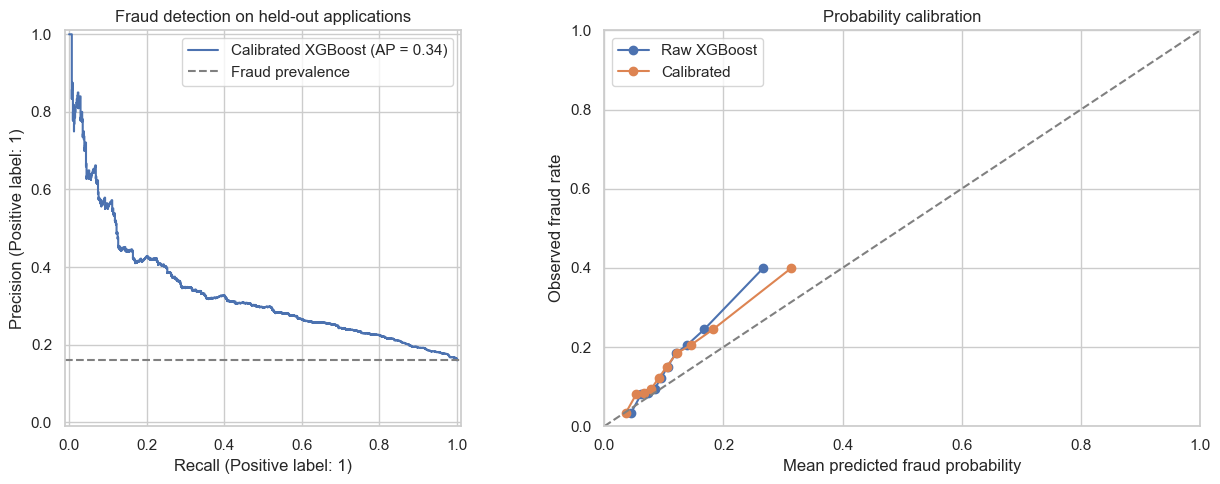

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    PrecisionRecallDisplay,
)

sns.set_theme(style="whitegrid", context="notebook")

raw_test_p = fraud_model.predict_proba(X["test"])[:, 1]

model_quality = pd.DataFrame([
    {
        "probabilities": label,
        "ROC_AUC": roc_auc_score(y["test"], probabilities),
        "average_precision": average_precision_score(
            y["test"], probabilities
        ),
        "Brier_score": brier_score_loss(
            y["test"], probabilities
        ),
    }
    for label, probabilities in [
        ("Raw", raw_test_p),
        ("Calibrated", p["test"]),
    ]
]).set_index("probabilities")

display(model_quality.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

PrecisionRecallDisplay.from_predictions(
    y["test"],
    p["test"],
    name="Calibrated XGBoost",
    ax=axes[0],
)

axes[0].axhline(
    y["test"].mean(),
    linestyle="--",
    color="gray",
    label="Fraud prevalence",
)

axes[0].set_title("Fraud detection on held-out applications")
axes[0].legend()

for label, probabilities in [
    ("Raw XGBoost", raw_test_p),
    ("Calibrated", p["test"]),
]:

    observed_rate, mean_probability = calibration_curve(
        y["test"],
        probabilities,
        n_bins=10,
        strategy="quantile",
    )

    axes[1].plot(
        mean_probability,
        observed_rate,
        marker="o",
        label=label,
    )

axes[1].plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray",
)

axes[1].set(
    title="Probability calibration",
    xlabel="Mean predicted fraud probability",
    ylabel="Observed fraud rate",
    xlim=(0, 1),
    ylim=(0, 1),
)

axes[1].legend()

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "01_model_quality.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

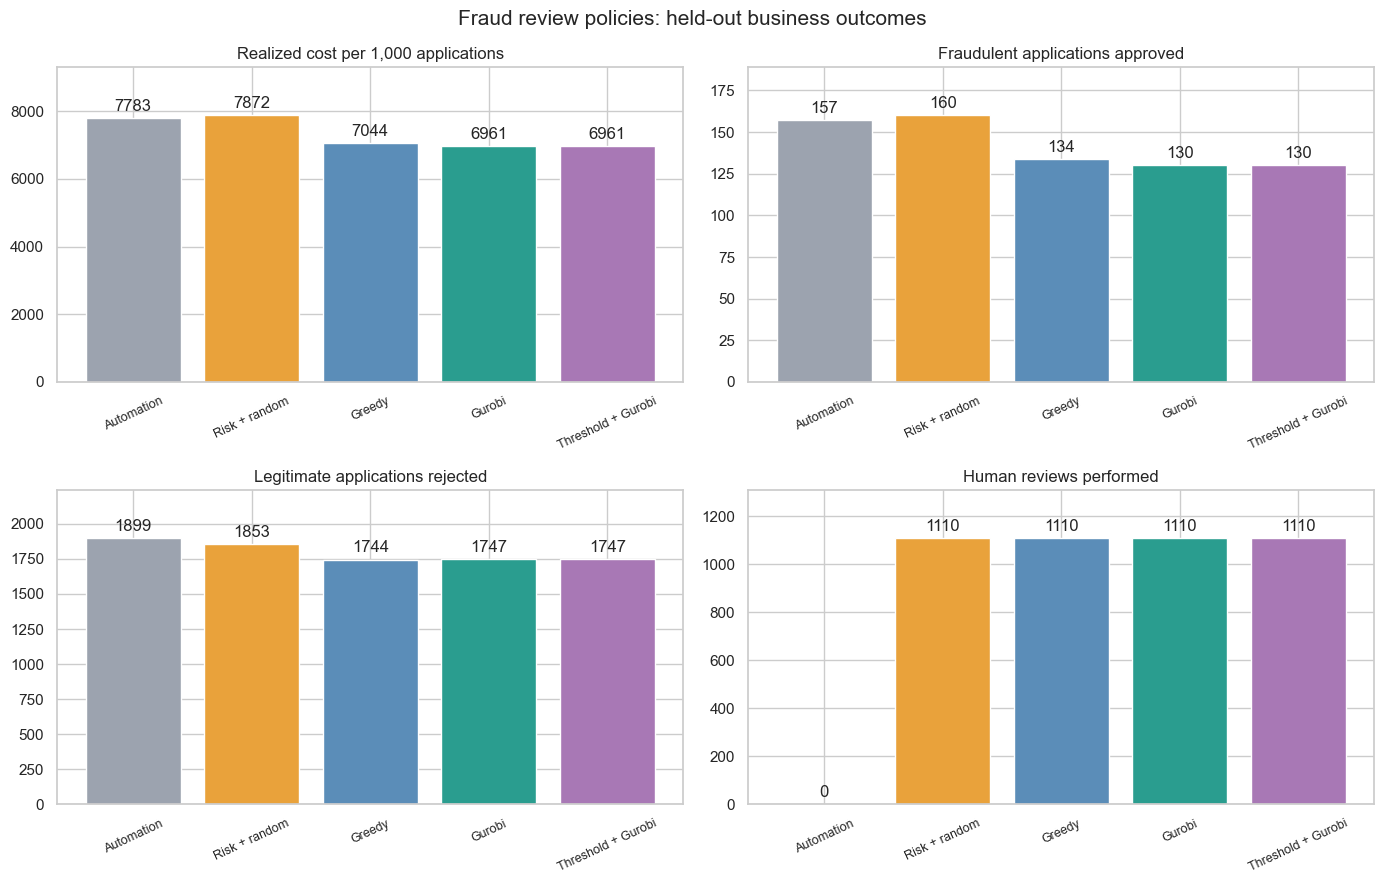

In [19]:
metrics_to_plot = [
    ("cost_per_1000", "Realized cost per 1,000 applications"),
    ("missed_fraud", "Fraudulent applications approved"),
    ("legit_rejected", "Legitimate applications rejected"),
    ("reviews", "Human reviews performed"),
]

colors = [
    "#9ca3af",
    "#e9a23b",
    "#5b8db8",
    "#2a9d8f",
    "#a878b5",
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (column, title) in zip(
    axes.ravel(),
    metrics_to_plot,
):

    bars = ax.bar(
        results.index,
        results[column],
        color=colors,
    )

    ax.set_title(title)
    ax.tick_params(axis="x", rotation=25, labelsize=9)
    ax.bar_label(bars, fmt="%.0f", padding=3)
    ax.margins(y=0.18)

fig.suptitle(
    "Fraud review policies: held-out business outcomes",
    fontsize=15,
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "02_business_results.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

Finished capacity: 0 slots per analyst
Finished capacity: 5 slots per analyst
Finished capacity: 10 slots per analyst
Finished capacity: 15 slots per analyst
Finished capacity: 20 slots per analyst

Capacity experiment preview:


,policy,slots_per_analyst,cost_per_1000,reviews,review_pct
0,Automation,0,7783.26,0,0.00
1,Risk + random,0,7783.26,0,0.00
2,Greedy,0,7783.26,0,0.00
3,Gurobi,0,7783.26,0,0.00
4,Automation,5,7783.26,0,0.00
5,Risk + random,5,7827.57,555,12.45
6,Greedy,5,7329.48,555,12.45
7,Gurobi,5,7311.53,555,12.45


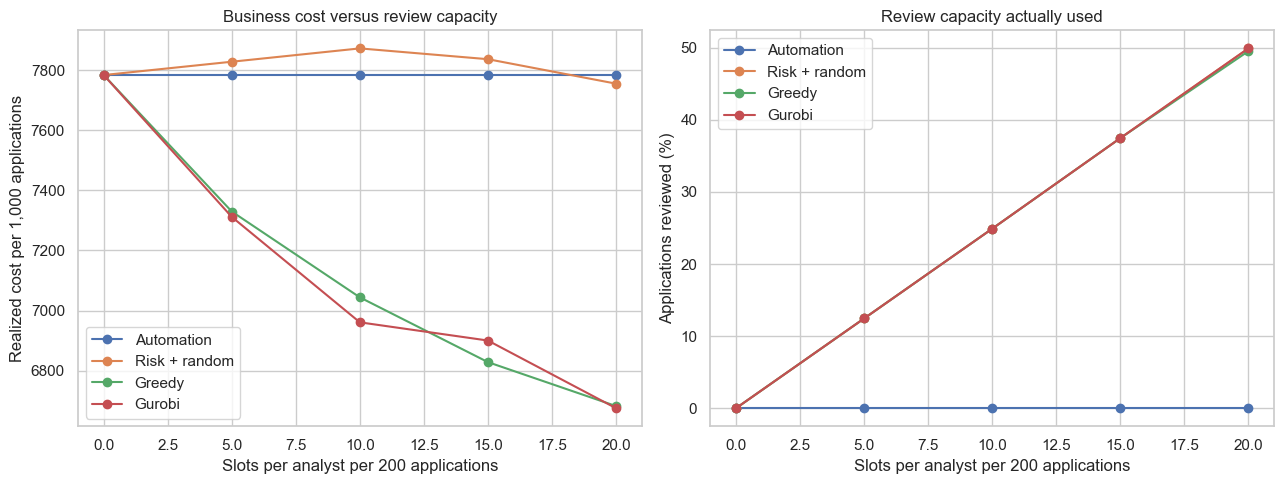

In [20]:
capacity_records = []

for slots in [0, 5, 10, 15, 20]:

    for policy in policies:

        actions = run_policy(
            costs["test"],
            p["test"],
            policy,
            slots_per_200=slots,
        )

        metrics = evaluate(
            actions,
            y["test"],
            H["test"],
        )

        metrics.update(
            policy=policy,
            slots_per_analyst=slots,
        )

        capacity_records.append(metrics)

    print(f"Finished capacity: {slots} slots per analyst")

capacity_results = pd.DataFrame(capacity_records)

print("\nCapacity experiment preview:")
display(
    capacity_results[
        [
            "policy",
            "slots_per_analyst",
            "cost_per_1000",
            "reviews",
            "review_pct",
        ]
    ].head(8).round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for policy in policies:

    subset = capacity_results.loc[
        capacity_results["policy"] == policy
    ].sort_values("slots_per_analyst")

    axes[0].plot(
        subset["slots_per_analyst"],
        subset["cost_per_1000"],
        marker="o",
        label=policy,
    )

    axes[1].plot(
        subset["slots_per_analyst"],
        subset["review_pct"],
        marker="o",
        label=policy,
    )

axes[0].set(
    title="Business cost versus review capacity",
    xlabel="Slots per analyst per 200 applications",
    ylabel="Realized cost per 1,000 applications",
)

axes[1].set(
    title="Review capacity actually used",
    xlabel="Slots per analyst per 200 applications",
    ylabel="Applications reviewed (%)",
)

for ax in axes:
    ax.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "03_capacity_tradeoff.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

Staffing experiment results:


,Predicted extra-slot saving,Realized extra-slot saving,Absence: reoptimize,Absence: fixed routing
analyst,,,,
standard#0,67.86,38.5,839.0,889.0
standard#1,79.97,-141.5,979.0,439.0
standard#2,83.42,48.5,1279.0,1039.0
standard#3,56.45,118.5,1109.0,919.0
standard#4,54.95,-41.5,-201.0,379.0


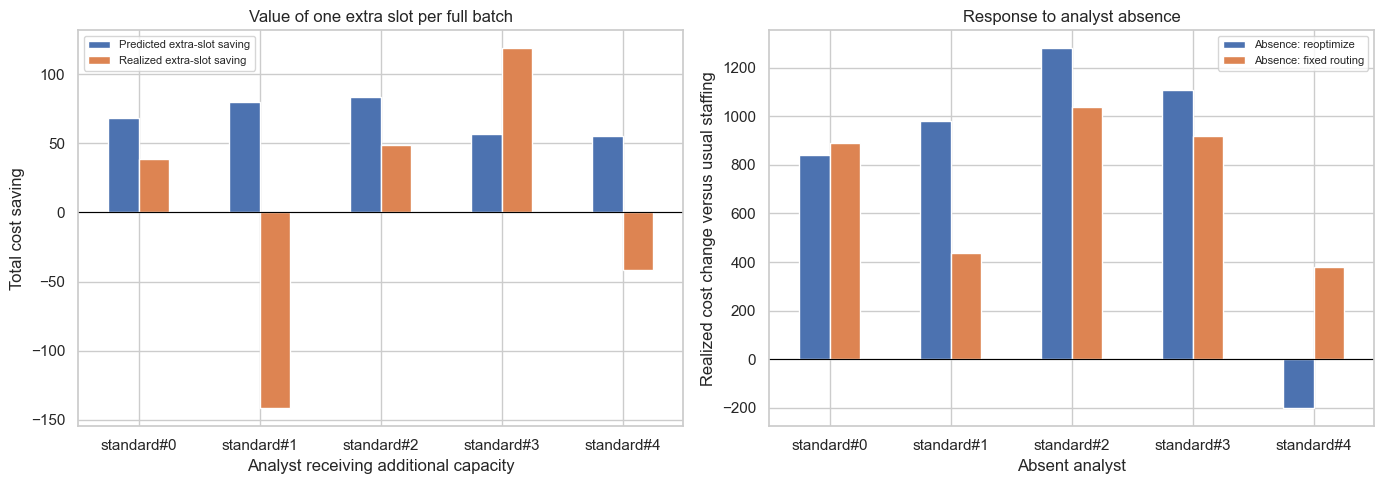

In [22]:
base_slots = np.full(N_ANALYSTS, SLOTS)

base_predicted_cost = results.loc[
    "Gurobi", "predicted_cost"
]

base_realized_cost = results.loc[
    "Gurobi", "total_cost"
]

automatic_test_actions = np.argmin(
    costs["test"][:, :2],
    axis=1,
)

staffing_records = []

for j, analyst in enumerate(ANALYSTS):

    # Experiment A: one extra slot for this analyst per full batch.
    extra_slots = base_slots.copy()
    extra_slots[j] += 1

    extra_actions = run_policy(
        costs["test"],
        p["test"],
        "Gurobi",
        slots_per_200=extra_slots,
    )

    extra_predicted_cost = costs["test"][
        np.arange(len(extra_actions)),
        extra_actions,
    ].sum()

    extra_metrics = evaluate(
        extra_actions,
        y["test"],
        H["test"],
    )

    # Experiment B: this analyst is absent.
    absent_slots = base_slots.copy()
    absent_slots[j] = 0

    reoptimized_actions = run_policy(
        costs["test"],
        p["test"],
        "Gurobi",
        slots_per_200=absent_slots,
    )

    assert not (reoptimized_actions == j + 2).any()

    reoptimized_metrics = evaluate(
        reoptimized_actions,
        y["test"],
        H["test"],
    )

    # Fixed-routing response:
    # retain other assignments and automate the absent analyst's cases.
    fixed_actions = test_actions["Gurobi"].copy()

    affected = fixed_actions == j + 2
    fixed_actions[affected] = automatic_test_actions[affected]

    fixed_metrics = evaluate(
        fixed_actions,
        y["test"],
        H["test"],
    )

    staffing_records.append({
        "analyst": analyst,
        "Predicted extra-slot saving":
            base_predicted_cost - extra_predicted_cost,
        "Realized extra-slot saving":
            base_realized_cost - extra_metrics["total_cost"],
        "Absence: reoptimize":
            reoptimized_metrics["total_cost"] - base_realized_cost,
        "Absence: fixed routing":
            fixed_metrics["total_cost"] - base_realized_cost,
    })

staffing = pd.DataFrame(
    staffing_records
).set_index("analyst")

assert staffing["Predicted extra-slot saving"].min() >= -1e-4

print("Staffing experiment results:")
display(staffing.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

staffing[
    [
        "Predicted extra-slot saving",
        "Realized extra-slot saving",
    ]
].plot.bar(
    ax=axes[0],
    rot=0,
)

axes[0].set(
    title="Value of one extra slot per full batch",
    xlabel="Analyst receiving additional capacity",
    ylabel="Total cost saving",
)

staffing[
    [
        "Absence: reoptimize",
        "Absence: fixed routing",
    ]
].plot.bar(
    ax=axes[1],
    rot=0,
)

axes[1].set(
    title="Response to analyst absence",
    xlabel="Absent analyst",
    ylabel="Realized cost change versus usual staffing",
)

for ax in axes:
    ax.axhline(0, color="black", linewidth=0.8)
    ax.legend(fontsize=8)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "05_staffing_experiments.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

Application-level audit preview:


,case_id,fraud_probability,action,actual_fraud,final_decision,routing_rule,realized_cost,risk_band
0,935715,0.131,standard#0,1,1,Flexible optimization,0.5,"(0.1, 0.2]"
1,935859,0.243,Reject,1,1,Flexible optimization,0.0,"(0.2, 0.3]"
2,990777,0.085,standard#3,0,0,Flexible optimization,0.5,"(-0.001, 0.1]"
3,910095,0.052,Approve,0,0,Flexible optimization,0.0,"(-0.001, 0.1]"
4,910958,0.093,standard#3,0,0,Flexible optimization,0.5,"(-0.001, 0.1]"
5,921643,0.038,Approve,0,0,Flexible optimization,0.0,"(-0.001, 0.1]"
6,960987,0.065,Approve,0,0,Flexible optimization,0.0,"(-0.001, 0.1]"
7,929660,0.029,Approve,0,0,Flexible optimization,0.0,"(-0.001, 0.1]"
8,918788,0.073,Approve,0,0,Flexible optimization,0.0,"(-0.001, 0.1]"
9,947803,0.065,standard#3,0,0,Flexible optimization,0.5,"(-0.001, 0.1]"



Action shares within each populated risk band:


action,Approve,Reject,standard#0,standard#1,standard#2,standard#3,standard#4
risk_band,,,,,,,
"(-0.001, 0.1]",0.725,0.047,0.038,0.041,0.041,0.052,0.054
"(0.1, 0.2]",0.000,0.648,0.080,0.078,0.076,0.061,0.057
"(0.2, 0.3]",0.000,0.965,0.012,0.000,0.009,0.006,0.009
"(0.3, 0.4]",0.000,1.000,0.000,0.000,0.000,0.000,0.000
"(0.4, 0.5]",0.000,1.000,0.000,0.000,0.000,0.000,0.000
"(0.5, 0.6]",0.000,1.000,0.000,0.000,0.000,0.000,0.000
"(0.6, 0.7]",0.000,1.000,0.000,0.000,0.000,0.000,0.000
"(0.7, 0.8]",0.000,1.000,0.000,0.000,0.000,0.000,0.000
"(0.8, 0.9]",0.000,1.000,0.000,0.000,0.000,0.000,0.000


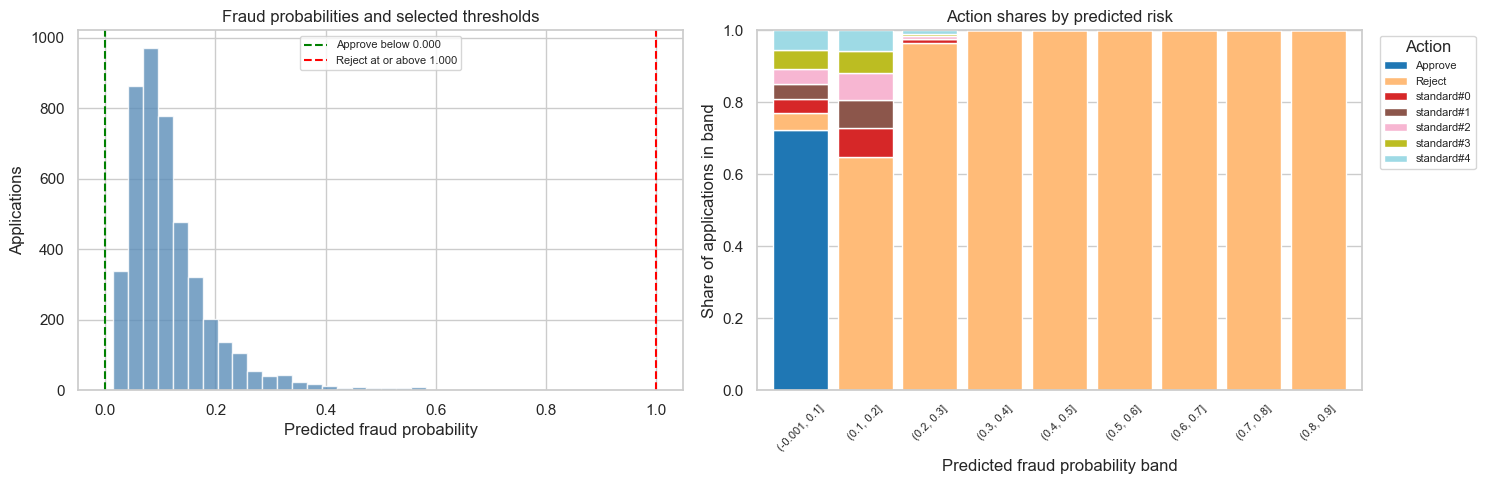

In [23]:
final_decisions = (
    extension_actions == 1
).astype(int)

reviewed_rows = np.flatnonzero(
    extension_actions >= 2
)

final_decisions[reviewed_rows] = H["test"][
    reviewed_rows,
    extension_actions[reviewed_rows] - 2,
]

audit = pd.DataFrame({
    "case_id": test_df.index.to_numpy(),
    "fraud_probability": p["test"],
    "action": ACTION_NAMES[extension_actions],
    "actual_fraud": y["test"],
    "final_decision": final_decisions,
})

audit["routing_rule"] = np.select(
    [
        p["test"] < LOWER,
        p["test"] >= UPPER,
    ],
    [
        "Forced approval",
        "Forced rejection",
    ],
    default="Flexible optimization",
)

audit["realized_cost"] = (
    C_FN
    * audit["actual_fraud"]
    * (1 - audit["final_decision"])
    + C_FP
    * (1 - audit["actual_fraud"])
    * audit["final_decision"]
    + C_REVIEW
    * (extension_actions >= 2)
)

audit["risk_band"] = pd.cut(
    audit["fraud_probability"],
    bins=np.linspace(0, 1, 11),
    include_lowest=True,
)

assert np.isclose(
    audit["realized_cost"].sum(),
    results.loc["Threshold + Gurobi", "total_cost"],
)

print("Application-level audit preview:")
display(audit.head(10).round(3))

routing_shares = pd.crosstab(
    audit["risk_band"],
    audit["action"],
    normalize="index",
).reindex(
    columns=ACTION_NAMES,
    fill_value=0,
)

print("\nAction shares within each populated risk band:")
display(routing_shares.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(
    p["test"],
    bins=30,
    color="#5b8db8",
    alpha=0.8,
)

axes[0].axvline(
    LOWER,
    color="green",
    linestyle="--",
    label=f"Approve below {LOWER:.3f}",
)

axes[0].axvline(
    UPPER,
    color="red",
    linestyle="--",
    label=f"Reject at or above {UPPER:.3f}",
)

axes[0].set(
    title="Fraud probabilities and selected thresholds",
    xlabel="Predicted fraud probability",
    ylabel="Applications",
)

axes[0].legend(fontsize=8)

routing_shares.plot.bar(
    stacked=True,
    ax=axes[1],
    colormap="tab20",
    width=0.85,
)

axes[1].set(
    title="Action shares by predicted risk",
    xlabel="Predicted fraud probability band",
    ylabel="Share of applications in band",
)

axes[1].tick_params(
    axis="x",
    rotation=45,
    labelsize=8,
)

axes[1].legend(
    title="Action",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8,
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "07_risk_routing.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()